In [1]:
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [2]:
# df = pd.read_excel("data/raw/Concrete_Data.xls")
# df.to_csv("concrete-data.csv", index=False)

In [3]:
np.set_printoptions(formatter={"float_kind": lambda x: f"{x:.1f}"})
pd.options.display.float_format = "{:.3f}".format

df = pd.read_csv("data/concrete-data.csv")
print(df.shape)

display(df.head())
df.columns = ["cement_kg_m3", "blast_furnace_slag_kg_m3", "fly_ash_kg_m3", "water_kg_m3", "superplasticizer_kg_m3", "coarse_aggregate_kg_m3", "fine_aggregate_kg_m3", "age_days", "compressive_strength_mpa"]
display(df.head())

(1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28,79.986
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28,61.887
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270,40.270
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365,41.053
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360,44.296


,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days,compressive_strength_mpa
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28,79.986
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28,61.887
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270,40.270
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365,41.053
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360,44.296


In [4]:
rng = np.random.default_rng(32)
features = df.drop(df.columns[-1], axis=1)
target = df.drop(df.columns[:-1], axis=1)
display(features)

flat_features = features.to_numpy().ravel()

PERCENTAGE = 0.05
SIZE = int(flat_features.size * PERCENTAGE)

index = rng.choice(flat_features.size, size=SIZE, replace=False)
print(index)

flat_features_nan = flat_features.copy()
flat_features_nan[index] = np.nan
print(flat_features_nan)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360
...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28


[6874 7172 6756  965 3405 8239 6246   68 1988 4319 2297 8049 7382 4638
 7857 7509 1550 6063 6911 2035 2795 1684 2040 2029 4481 2028 4512 2294
  250 4012 6330 4588 6709 6962 1198  284 4767 5419  151 6779 1800 1720
 7675 1326  650 3627 4113 5381  330 2278 1875  595 4652 1162 5777 4667
 4247 2771 1192 7275 6810 4515 6186 6006 5594  267 1147 1132 6525  433
 5969  772 3319 4256 6398 7455 6943 2794 6331 1108  191 4547 3035 5311
 5807 7605 4676 7314 2709 2495 3682 2659 1743 7914  393 1076 3269 5686
 4983 2155 4642 4925 2556 2269 3619 3948 3247 8070 3123 6495 8169 5583
 1080 3336  320  367 4187  415 3616 6305 8191 6029 2489 6094  664 3209
 3522 5147 3639 5998 6397 1254 5882 2883  537 4231  184 7467 5400 7256
 7772 3799 7860 1859 1208 1846 2829 1583 5346 2555 5521 6045 2715 6394
 1579 4330 1782 6401 2722 1900 2787 7536 2480 4843  249 4981 6674 8186
 4041  629 1725 7880  352  227 8158 6421  643 2360 2308 4875  311 7370
 7903 5721 3488  623 1106 5836 7483  833  899 7116 5654 4260 5243 6200
 1375 

In [5]:
reshaped = flat_features_nan.reshape(features.shape)
print(reshaped)
features_nan = pd.DataFrame(
    reshaped,
    columns=features.columns,
    index=features.index
)
display(features_nan)

[[540.0 0.0 0.0 ... 1040.0 676.0 28.0]
 [540.0 0.0 0.0 ... 1055.0 676.0 28.0]
 [332.5 142.5 0.0 ... 932.0 594.0 270.0]
 ...
 [148.5 139.4 108.6 ... 892.4 780.0 28.0]
 [159.1 186.7 0.0 ... 989.6 788.9 28.0]
 [260.9 100.5 78.3 ... 864.5 761.5 nan]]


,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28.000
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28.000
2,332.500,142.500,0.000,228.000,NaN,932.000,594.000,270.000
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365.000
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360.000
...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28.000
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28.000
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28.000
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28.000


In [24]:
mask = np.zeros(features.shape, dtype=bool)
mask.ravel()[index] = True
print(mask)

[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False  True]]


In [7]:
features_median = features_nan.fillna(features_nan.median())
display(features_median)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28.000
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28.000
2,332.500,142.500,0.000,228.000,6.350,932.000,594.000,270.000
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365.000
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360.000
...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28.000
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28.000
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28.000
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28.000


In [8]:
results_median = []
for i, column in enumerate(features.columns):
    y_true = features.iloc[:, i].to_numpy()[mask[:, i]]
    y_pred = features_median.iloc[:, i].to_numpy()[mask[:, i]]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results_median.append({
        "method": "Median",
        "feature": column,
        "mae": mae,
        "rmse": rmse,
        "r2": r2
    })
results_median = pd.DataFrame(results_median)
display(results_median)

,method,feature,mae,rmse,r2
0,Median,cement_kg_m3,83.023,101.971,-0.000
1,Median,blast_furnace_slag_kg_m3,72.778,101.140,-0.358
2,Median,fly_ash_kg_m3,59.348,87.798,-0.841
3,Median,water_kg_m3,18.391,24.337,-0.245
4,Median,superplasticizer_kg_m3,4.255,4.991,-0.000
5,Median,coarse_aggregate_kg_m3,76.535,91.424,-0.052
6,Median,fine_aggregate_kg_m3,69.904,90.225,-0.011
7,Median,age_days,28.491,60.030,-0.061


In [9]:
features_mean = features_nan.fillna(features_nan.mean())
display(features_mean)



,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28.000
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28.000
2,332.500,142.500,0.000,228.000,6.192,932.000,594.000,270.000
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365.000
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360.000
...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28.000
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28.000
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28.000
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28.000


In [10]:
results_mean = []
for i, column in enumerate(features.columns):
    y_true = features.iloc[:, i].to_numpy()[mask[:, i]]
    y_pred = features_mean.iloc[:, i].to_numpy()[mask[:, i]]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results_mean.append({
        "method": "Mean",
        "feature": column,
        "mae": mae,
        "rmse": rmse,
        "r2": r2
    })
results_mean = pd.DataFrame(results_mean)
display(results_mean)

,method,feature,mae,rmse,r2
0,Mean,cement_kg_m3,82.880,102.370,-0.008
1,Mean,blast_furnace_slag_kg_m3,77.448,86.802,-0.000
2,Mean,fly_ash_kg_m3,60.427,64.933,-0.007
3,Mean,water_kg_m3,17.555,22.932,-0.106
4,Mean,superplasticizer_kg_m3,4.260,4.995,-0.002
5,Mean,coarse_aggregate_kg_m3,76.410,90.553,-0.032
6,Mean,fine_aggregate_kg_m3,69.756,89.774,-0.001
7,Mean,age_days,36.604,58.396,-0.004


In [11]:
K = 3
knn_imputer = KNNImputer(n_neighbors=K)
knn_imputer.set_output(transform="pandas")
features_knn = knn_imputer.fit_transform(features_nan)

knn_imputer_5 = KNNImputer(n_neighbors=5)
knn_imputer_5.set_output(transform="pandas")
features_knn_5 = knn_imputer_5.fit_transform(features_nan)

knn_imputer_10 = KNNImputer(n_neighbors=10)
knn_imputer_10.set_output(transform="pandas")
features_knn_10 = knn_imputer_10.fit_transform(features_nan)
display(features_knn)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28.000
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28.000
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270.000
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365.000
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360.000
...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28.000
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28.000
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28.000
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28.000


In [12]:
results_knn = []
for i, column in enumerate(features.columns):
    y_true = features.iloc[:, i].to_numpy()[mask[:, i]]
    y_pred = features_knn.iloc[:, i].to_numpy()[mask[:, i]]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results_knn.append({
        "method": "KNN3",
        "feature": column,
        "mae": mae,
        "rmse": rmse,
        "r2": r2
    })
results_knn = pd.DataFrame(results_knn)
display(results_knn)

,method,feature,mae,rmse,r2
0,KNN3,cement_kg_m3,29.985,46.347,0.793
1,KNN3,blast_furnace_slag_kg_m3,17.207,29.648,0.883
2,KNN3,fly_ash_kg_m3,13.785,25.655,0.843
3,KNN3,water_kg_m3,5.898,10.208,0.781
4,KNN3,superplasticizer_kg_m3,1.054,1.638,0.892
5,KNN3,coarse_aggregate_kg_m3,21.205,39.286,0.806
6,KNN3,fine_aggregate_kg_m3,26.822,44.849,0.750
7,KNN3,age_days,37.206,63.571,-0.189


In [13]:
results_knn_5 = []
for i, column in enumerate(features.columns):
    y_true = features.iloc[:, i].to_numpy()[mask[:, i]]
    y_pred = features_knn_5.iloc[:, i].to_numpy()[mask[:, i]]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results_knn_5.append({
        "method": "KNN5",
        "feature": column,
        "mae": mae,
        "rmse": rmse,
        "r2": r2
    })
results_knn_5 = pd.DataFrame(results_knn_5)
display(results_knn_5)

,method,feature,mae,rmse,r2
0,KNN5,cement_kg_m3,37.420,50.362,0.756
1,KNN5,blast_furnace_slag_kg_m3,21.068,32.579,0.859
2,KNN5,fly_ash_kg_m3,15.287,27.014,0.826
3,KNN5,water_kg_m3,6.937,11.542,0.720
4,KNN5,superplasticizer_kg_m3,1.270,1.994,0.840
5,KNN5,coarse_aggregate_kg_m3,23.948,39.472,0.804
6,KNN5,fine_aggregate_kg_m3,30.302,44.900,0.750
7,KNN5,age_days,38.593,64.217,-0.214


In [14]:
results_knn_10 = []
for i, column in enumerate(features.columns):
    y_true = features.iloc[:, i].to_numpy()[mask[:, i]]
    y_pred = features_knn_10.iloc[:, i].to_numpy()[mask[:, i]]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results_knn_10.append({
        "method": "KNN10",
        "feature": column,
        "mae": mae,
        "rmse": rmse,
        "r2": r2
    })
results_knn_10 = pd.DataFrame(results_knn_10)
display(results_knn_10)

,method,feature,mae,rmse,r2
0,KNN10,cement_kg_m3,41.461,52.262,0.737
1,KNN10,blast_furnace_slag_kg_m3,27.788,39.957,0.788
2,KNN10,fly_ash_kg_m3,18.404,31.325,0.766
3,KNN10,water_kg_m3,8.370,11.554,0.719
4,KNN10,superplasticizer_kg_m3,1.657,2.357,0.777
5,KNN10,coarse_aggregate_kg_m3,26.151,39.178,0.807
6,KNN10,fine_aggregate_kg_m3,37.984,57.130,0.594
7,KNN10,age_days,38.022,64.495,-0.224


In [15]:
iterative_imputer = IterativeImputer(random_state=32, tol=1e-2)
iterative_imputer.set_output(transform="pandas")
features_iterative = iterative_imputer.fit_transform(features_nan)
display(features_iterative)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28.000
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28.000
2,332.500,142.500,0.000,228.000,-0.086,932.000,594.000,270.000
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365.000
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360.000
...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28.000
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28.000
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28.000
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28.000


In [16]:
results_iterative = []
for i, column in enumerate(features.columns):
    y_true = features.iloc[:, i].to_numpy()[mask[:, i]]
    y_pred = features_iterative.iloc[:, i].to_numpy()[mask[:, i]]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results_iterative.append({
        "method": "Iterative",
        "feature": column,
        "mae": mae,
        "rmse": rmse,
        "r2": r2
    })
results_iterative = pd.DataFrame(results_iterative)
display(results_iterative)

,method,feature,mae,rmse,r2
0,Iterative,cement_kg_m3,38.409,49.316,0.766
1,Iterative,blast_furnace_slag_kg_m3,28.406,36.678,0.821
2,Iterative,fly_ash_kg_m3,23.413,30.103,0.784
3,Iterative,water_kg_m3,7.257,9.742,0.800
4,Iterative,superplasticizer_kg_m3,2.443,3.208,0.587
5,Iterative,coarse_aggregate_kg_m3,34.634,44.849,0.747
6,Iterative,fine_aggregate_kg_m3,29.169,39.290,0.808
7,Iterative,age_days,37.413,58.319,-0.001


In [17]:
rforest_imputer = IterativeImputer(estimator=RandomForestRegressor(random_state=32), random_state=32, tol=1e-2)
rforest_imputer.set_output(transform="pandas")
features_rforest = rforest_imputer.fit_transform(features_nan)
display(features_rforest)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days
0,540.000,0.000,0.000,162.000,2.500,1040.000,676.000,28.000
1,540.000,0.000,0.000,162.000,2.500,1055.000,676.000,28.000
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270.000
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365.000
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360.000
...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28.000
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28.000
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28.000
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28.000


In [18]:
results_rforest = []
for i, column in enumerate(features.columns):
    y_true = features.iloc[:, i].to_numpy()[mask[:, i]]
    y_pred = features_rforest.iloc[:, i].to_numpy()[mask[:, i]]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results_rforest.append({
        "method": "R_Forest",
        "feature": column,
        "mae": mae,
        "rmse": rmse,
        "r2": r2
    })
results_rforest = pd.DataFrame(results_rforest)
display(results_rforest)

,method,feature,mae,rmse,r2
0,R_Forest,cement_kg_m3,14.667,37.446,0.865
1,R_Forest,blast_furnace_slag_kg_m3,10.764,31.601,0.867
2,R_Forest,fly_ash_kg_m3,9.649,28.403,0.807
3,R_Forest,water_kg_m3,2.746,7.792,0.872
4,R_Forest,superplasticizer_kg_m3,0.735,1.721,0.881
5,R_Forest,coarse_aggregate_kg_m3,8.394,18.221,0.958
6,R_Forest,fine_aggregate_kg_m3,5.291,13.208,0.978
7,R_Forest,age_days,38.911,66.874,-0.316


In [19]:
all_results = pd.concat([
    results_mean,
    results_median,
    results_knn,
    results_knn_5,
    results_knn_10,
    results_iterative,
    results_rforest
], ignore_index=True)

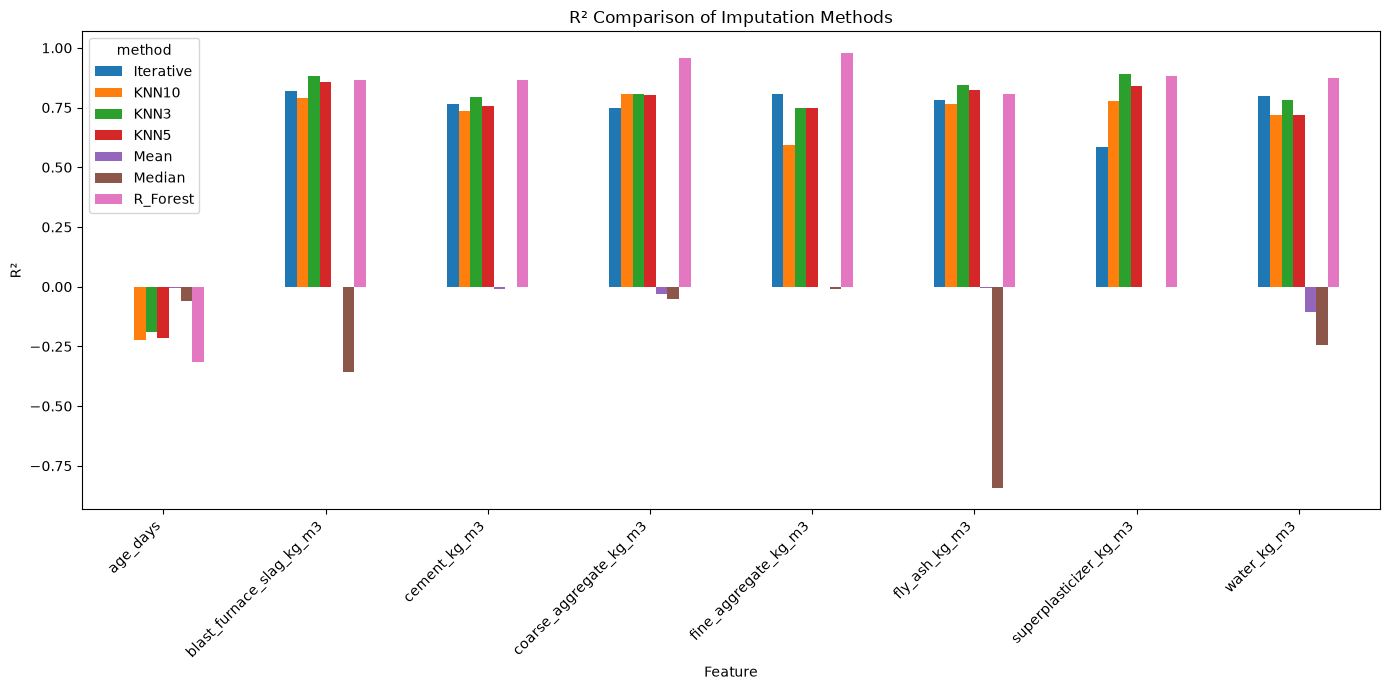

In [20]:
r2_table = all_results.pivot(
    index="feature",
    columns="method",
    values="r2"
)

r2_table.plot(kind="bar", figsize=(14, 7))

plt.title("R² Comparison of Imputation Methods")
plt.xlabel("Feature")
plt.ylabel("R²")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("charts/r2-comparison.png", dpi=300, bbox_inches="tight")
plt.show()

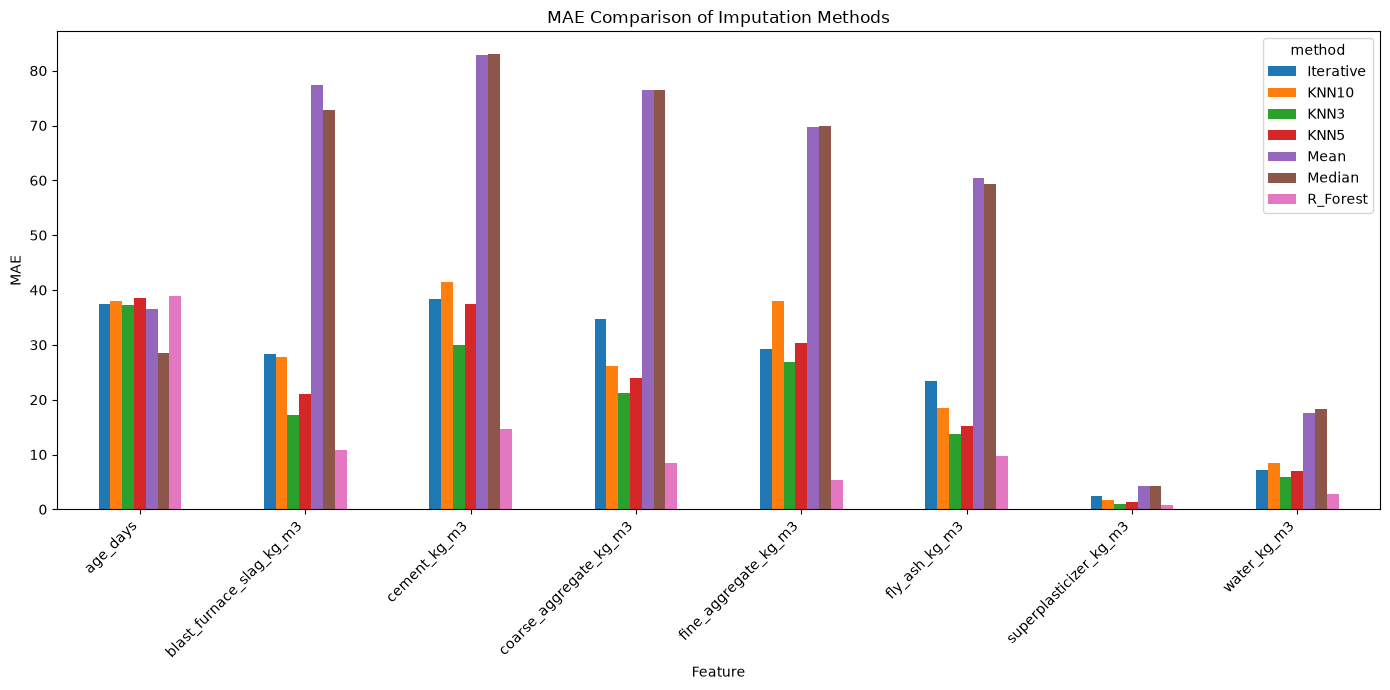

In [21]:
mae_table = all_results.pivot(
    index="feature",
    columns="method",
    values="mae"
)

mae_table.plot(kind="bar", figsize=(14, 7))

plt.title("MAE Comparison of Imputation Methods")
plt.xlabel("Feature")
plt.ylabel("MAE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("charts/mae-comparison.png", dpi=300, bbox_inches="tight")
plt.show()

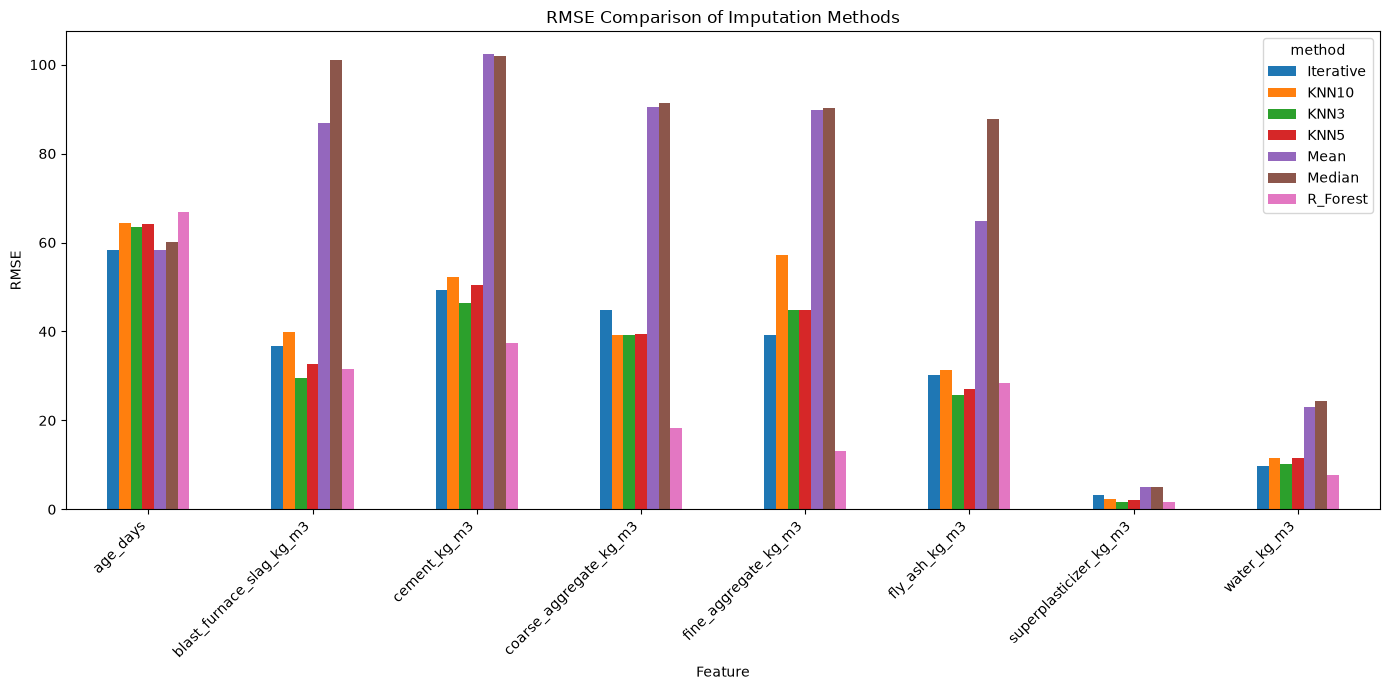

In [22]:
rmse_table = all_results.pivot(
    index="feature",
    columns="method",
    values="rmse"
)

rmse_table.plot(kind="bar", figsize=(14, 7))

plt.title("RMSE Comparison of Imputation Methods")
plt.xlabel("Feature")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("charts/rmse-comparison.png", dpi=300, bbox_inches="tight")
plt.show()